In [10]:
import json
from collections import defaultdict

# JSON 파일 읽기
def read_json_file(file_path):
    with open(file_path, 'r', encoding='utf-8') as file:
        data = [json.loads(line) for line in file]
    return data


def time_to_minutes(time_str):
    parts = time_str.split(':')
    if len(parts) == 3:  # 형식이 "1:11:03"와 같은 경우
        hours, minutes, _ = map(int, parts)
        return hours * 60 + minutes
    elif len(parts) == 2:  # 형식이 "11:03"와 같은 경우
        minutes, _ = map(int, parts)
        return minutes
    else:
        return None  # 알 수 없는 형식

def count_messages_per_minute(messages):
    message_counts = defaultdict(int)
    for message in messages:
        time = message['time']
        minutes = time_to_minutes(time)
        if minutes is not None and minutes >= 0:  # 0초 이상인 경우만 처리
            message_counts[minutes] += 1
    return message_counts


In [11]:
file_path = "./youtube_livechat_replay_crawler/chatlog_replay_Cbij3MKhdOY.json"  # JSON 파일 경로를 지정해주세요

chat_data = read_json_file(file_path)

message_counts = count_messages_per_minute(chat_data)

for minute, count in sorted(message_counts.items()):
    print(f"{minute}: {count} messages")


0: 28 messages
1: 47 messages
2: 33 messages
3: 22 messages
4: 10 messages
5: 10 messages
6: 18 messages
7: 10 messages
8: 12 messages
9: 9 messages
10: 10 messages
11: 12 messages
12: 15 messages
13: 29 messages
14: 27 messages
15: 29 messages
16: 25 messages
17: 24 messages
18: 17 messages
19: 17 messages
20: 12 messages
21: 21 messages
22: 31 messages
23: 25 messages
24: 23 messages
25: 17 messages
26: 18 messages
27: 12 messages
28: 22 messages
29: 13 messages
30: 27 messages
31: 25 messages
32: 42 messages
33: 39 messages
34: 31 messages
35: 29 messages
36: 35 messages
37: 32 messages
38: 46 messages
39: 54 messages
40: 53 messages
41: 62 messages
42: 83 messages
43: 64 messages
44: 47 messages
45: 30 messages
46: 26 messages
47: 56 messages
48: 57 messages
49: 36 messages
50: 48 messages
51: 39 messages
52: 50 messages
53: 90 messages
54: 44 messages
55: 47 messages
56: 52 messages
57: 43 messages
58: 61 messages
59: 75 messages
60: 49 messages
61: 36 messages
62: 94 messages
63:

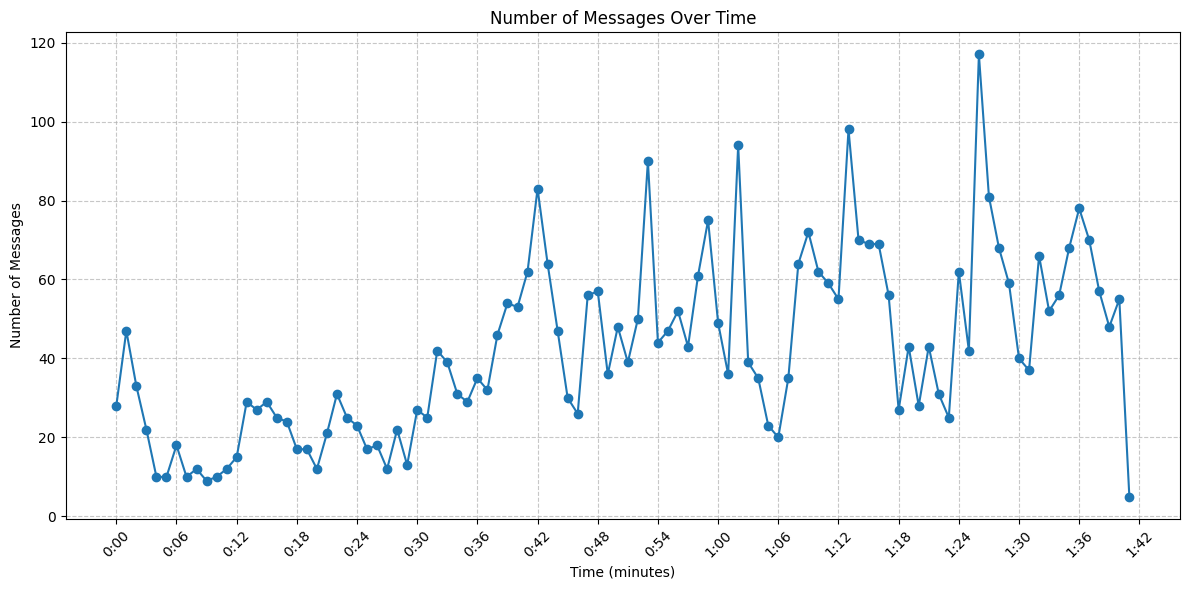

In [12]:
import matplotlib.pyplot as plt

minutes = sorted(message_counts.keys())
counts = [message_counts[m] for m in minutes]

plt.figure(figsize=(12, 6))
plt.plot(minutes, counts, marker='o')
plt.title('Number of Messages Over Time')
plt.xlabel('Time (minutes)')
plt.ylabel('Number of Messages')

# X축 레이블 조정
plt.xticks(rotation=45)
plt.gca().xaxis.set_major_locator(plt.MaxNLocator(20))  # X축 틱 개수 조정

# X축 레이블을 시:분 형식으로 변경
def format_time(x, pos):
    hours, mins = divmod(int(x), 60)
    return f'{hours}:{mins:02d}'

plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(format_time))

plt.tight_layout()
plt.grid(True, linestyle='--', alpha=0.7)
plt.savefig('message_count_graph.png')
plt.show()

# MRD

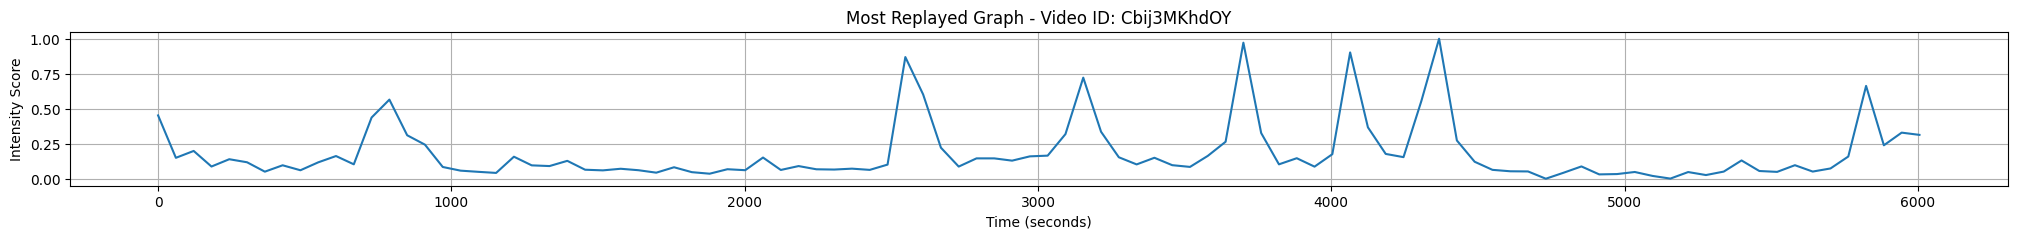

In [13]:

# 동영상 ID
video_id = "Cbij3MKhdOY"
event_lst = [13, 15, 21, 43, 45, 52, 62, 68, 73, 97]
start = 40
end = 97
json_path = f'/source/ms/highlight/json/{video_id}.json'
with open(json_path, 'r') as json_file:
    data = json.load(json_file)


markers = data['items'][0]['mostReplayed']['markers']
start_millis = [marker['startMillis'] for marker in markers]
intensity_scores = [marker['intensityScoreNormalized'] for marker in markers]

# 밀리초를 초로 변환
start_seconds = [millis / 1000 for millis in start_millis]

# 그래프 그리기
plt.figure(figsize=(25, 2))
plt.plot(start_seconds, intensity_scores)
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()


In [14]:
total_duration_minutes

100.089

# 유사도 비교


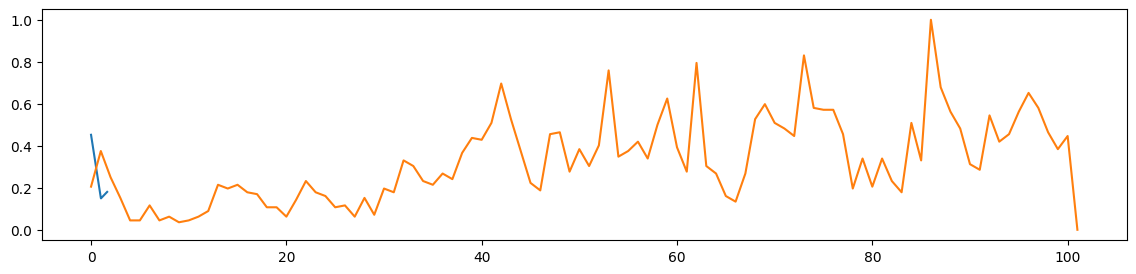

In [15]:
plt.figure(figsize=(14, 3))
plt.plot(new_time / 60, smoothed_intensity_scores)  # 분으로 변환하여 표시


min_count = min(counts)
max_count = max(counts)
normalized_counts = [(count - min_count) / (max_count - min_count) for count in counts]

plt.plot(minutes, normalized_counts)



In [16]:
 len(intensity_scores)

100

Pearson 상관계수: 0.333446900464392
P-value: 0.0006986321681486711


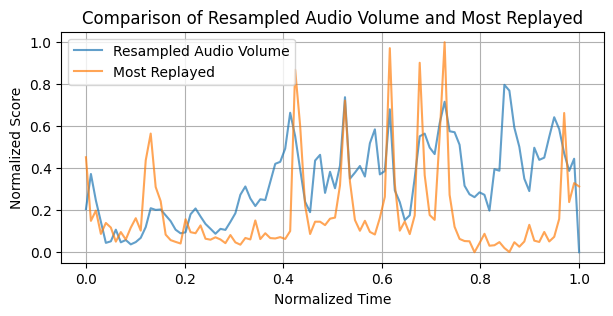

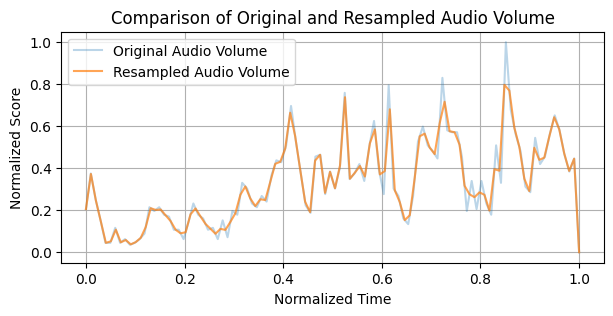

In [20]:
import numpy as np
from scipy import interpolate, stats
import matplotlib.pyplot as plt

# 리샘플링 함수
def resample(x, y, num_points):
    f = interpolate.interp1d(x, y, kind='linear', fill_value='extrapolate')
    x_new = np.linspace(x.min(), x.max(), num_points)
    y_new = f(x_new)
    return x_new, y_new

# 원본 데이터의 x 축 (시간) 생성
x_chat_speed = np.linspace(0, 1, len(minutes))
x_scores = np.linspace(0, 1, len(intensity_scores))

# normalize_ma_rms_cropped를 normalize_scores_cropped의 길이에 맞춰 리샘플링
x_resampled, y_resampled = resample(x_chat_speed, normalized_counts, len(intensity_scores))

# Pearson 상관계수 계산
correlation, p_value = stats.pearsonr(y_resampled, intensity_scores)

print(f"Pearson 상관계수: {correlation}")
print(f"P-value: {p_value}")

# 시각화
plt.figure(figsize=(7, 3))
plt.plot(x_resampled, y_resampled, label='Resampled Audio Volume', alpha=0.7)
plt.plot(x_scores, intensity_scores, label='Most Replayed', alpha=0.7)
plt.title('Comparison of Resampled Audio Volume and Most Replayed')
plt.xlabel('Normalized Time')
plt.ylabel('Normalized Score')
plt.legend()
plt.grid(True)
plt.show()

# 원본 데이터와 리샘플링된 데이터 비교 (선택적)
plt.figure(figsize=(7, 3))
plt.plot(x_chat_speed, normalized_counts, label='Original Audio Volume', alpha=0.3)
plt.plot(x_resampled, y_resampled, label='Resampled Audio Volume', alpha=0.7)
plt.title('Comparison of Original and Resampled Audio Volume')
plt.xlabel('Normalized Time')
plt.ylabel('Normalized Score')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
len(smoothed_intensity_scores)

6006